In [10]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from sklearn.preprocessing import MinMaxScaler
from sklearn.impute import KNNImputer

# Load both CSV files
#windows
#train_df = pd.read_csv("D:/Data_Projects\MCcharacterisation/ROSMAP/_core_data/ROSMAP_train_projid.csv")
#test_df = pd.read_csv("D:/Data_Projects\MCcharacterisation/ROSMAP/_core_data/ROSMAP_validate_projid.csv")
#pheno = pd.read_excel('D:/Data_Projects/MCcharacterisation/ROSMAP/_core_data/pheno_filt_touse.xlsx')


#MacOS
train_df = pd.read_csv("/Users/ga0028vi/Documents/MCcharactertization/ROSMAP/_core_data/Split_33_33_33/ROSMAP_train_projid.csv")
validate_df = pd.read_csv("/Users/ga0028vi/Documents/MCcharactertization/ROSMAP/_core_data/Split_33_33_33/ROSMAP_validate_projid.csv")
test_df = pd.read_csv('/Users/ga0028vi/Documents/MCcharactertization/ROSMAP/_core_data/Split_33_33_33/ROSMAP_test_projid.csv')
pheno = pd.read_excel('/Users/ga0028vi/Documents/MCcharactertization/ROSMAP/_core_data/dataset_1125_basic_01102022.xlsx')


In [11]:
# Combine projid columns
combined_projids = pd.concat([train_df['projid'], test_df['projid'], validate_df['projid']])

pheno_subset = pheno[pheno['projid'].isin(combined_projids)]
pheno_subset.set_index(pheno_subset.columns[0], inplace=True)

In [12]:
pheno

,projid,study,scaled_to,apoe_genotype,tomm40_hap,age_first_ad_dx,cogdx,cognep_demog_slope,cognep_path_slope,cogng_demog_slope,...,tangles_it,tangles_mf,tangles_sf,tangsqrt,tdp_st4,arteriol_scler,caa_4gp,cvda_4gp2,ci_num2_gct,ci_num2_mct
0,9121,MAP,ROSMAP,34.0,2.0,NaN,NaN,0.055460,NaN,0.043206,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,21073,ROS,ROSMAP,34.0,NaN,NaN,4.0,-0.204777,-0.003202,-0.175540,...,90.51285,42.6499,38.4887,6.38974,3.0,0.0,3.0,2.0,0.0,1.0
2,33027,MAP,ROSMAP,33.0,3.0,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,45071,MAP,ROSMAP,NaN,NaN,88.528405,NaN,NaN,NaN,-0.088362,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,130005,MAP,ROSMAP,NaN,NaN,NaN,NaN,0.020325,NaN,0.022429,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3684,99872367,MAP,ROSMAP,NaN,NaN,NaN,NaN,-0.083229,NaN,0.005221,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3685,99893592,MAP,ROSMAP,33.0,NaN,NaN,NaN,0.103092,NaN,0.077454,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3686,99911705,MAP,ROSMAP,23.0,1.0,91.578371,NaN,-0.015267,NaN,0.002573,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3687,99978916,ROS,ROSMAP,33.0,NaN,NaN,NaN,0.038062,NaN,0.027327,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


PRE-IMPUTATIONS AND SCALING


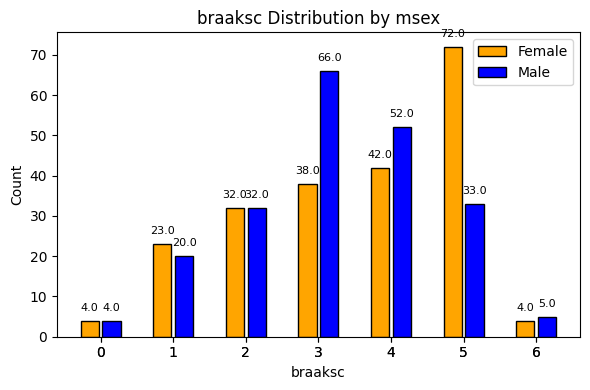

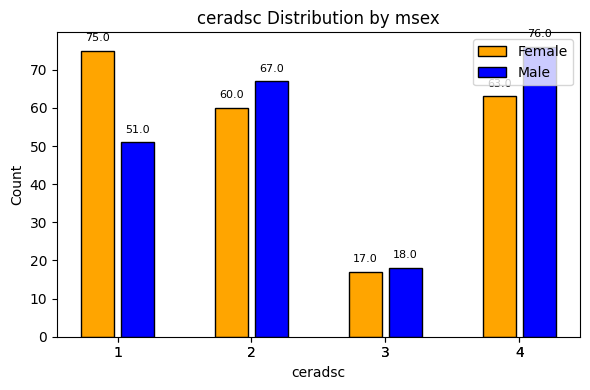

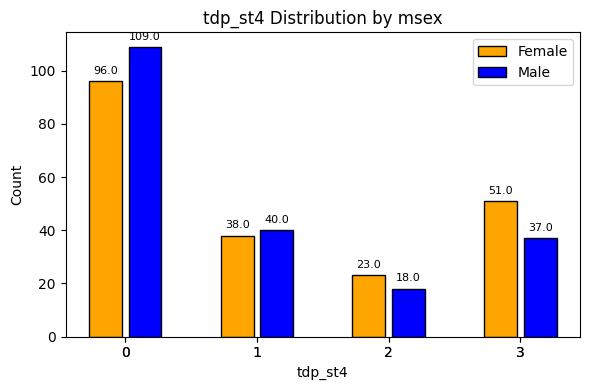

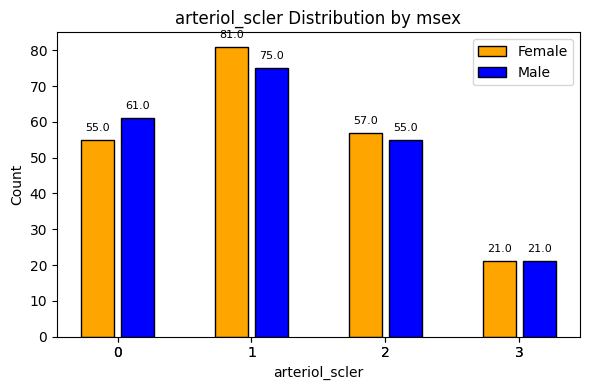

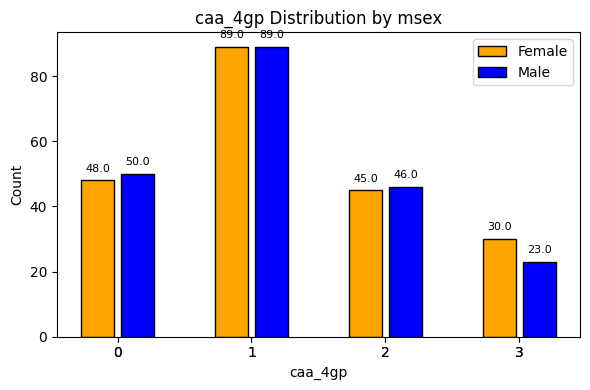

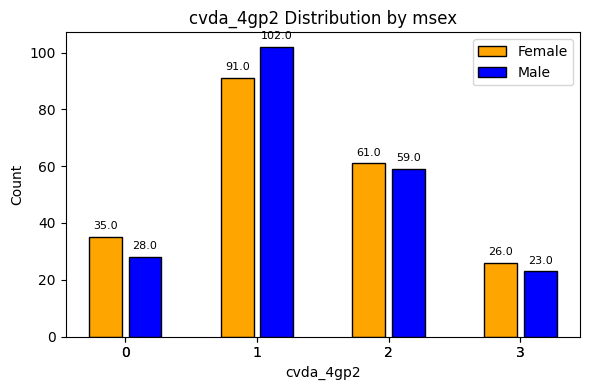

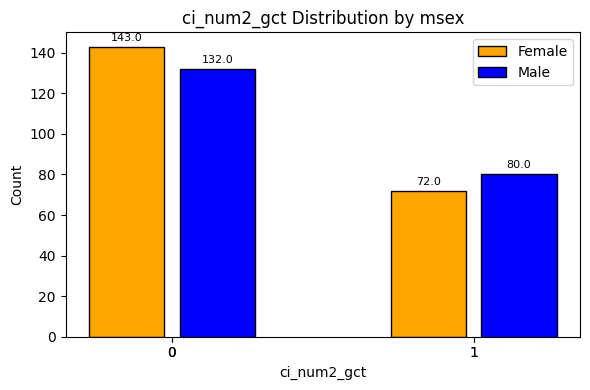

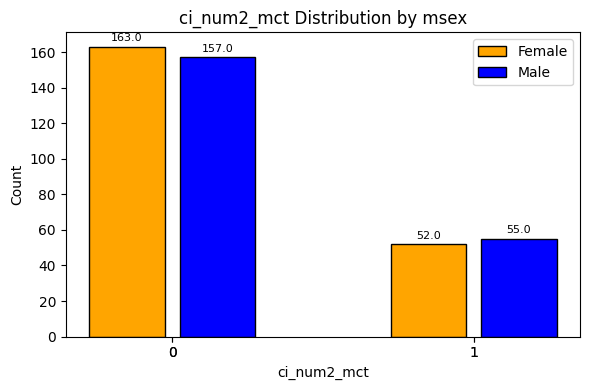

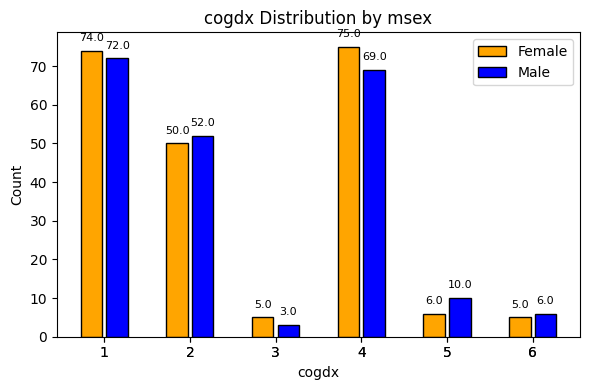

In [15]:
print('PRE-IMPUTATIONS AND SCALING')
# Select only numeric columns you're interested in
categorical_vars = ['braaksc', 'ceradsc',
        'tdp_st4',
       'arteriol_scler', 'caa_4gp', 'cvda_4gp2', 'ci_num2_gct', 'ci_num2_mct',
        'cogdx', 'E2', 'E4', 'new_cogdx']

group_col = 'msex'

# Colors for different sexes
sex_labels = {1: "Male", 0: "Female"}
colors = {1: 'blue', 0: 'orange'}

for col in categorical_vars:
    plt.figure(figsize=(6, 4))

    # Count by phenotype value and sex
    count_data = pheno_subset.groupby([col, group_col]).size().reset_index(name='count')

    # Create a spacing-aware x-axis: (phenotype * 10) + offset for sex
    x_ticks = []
    bar_labels = []
    bar_positions = []
    counts = []

    for i, row in count_data.iterrows():
        pheno_val = int(row[col])
        sex = row[group_col]
        count = row['count']
        # Position: spread by phenotype value, offset males/females slightly
        base_x = pheno_val * 10
        offset = -1.5 if sex == 0 else 1.5
        x = base_x + offset

        plt.bar(x, count, width=2.5, color=colors[sex], label=sex_labels[sex] if x not in bar_positions else "", edgecolor='black')
        plt.text(x, count + 2, str(count), ha='center', va='bottom', fontsize=8)

        x_ticks.append(base_x)
        counts.append(count)
        bar_labels.append(str(pheno_val))
        bar_positions.append(x)

    # Remove duplicate legends
    handles, labels = plt.gca().get_legend_handles_labels()
    by_label = dict(zip(labels, handles))
    plt.legend(by_label.values(), by_label.keys())

    plt.xticks(x_ticks, bar_labels)
    plt.title(f"{col} Distribution by msex")
    plt.xlabel(col)
    plt.ylabel("Count")
    plt.tight_layout()
    plt.show()
    plt.close()

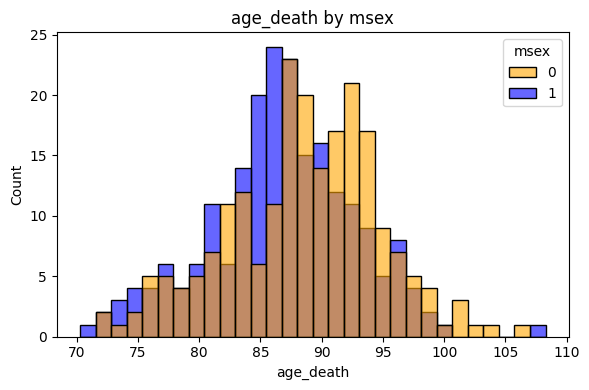

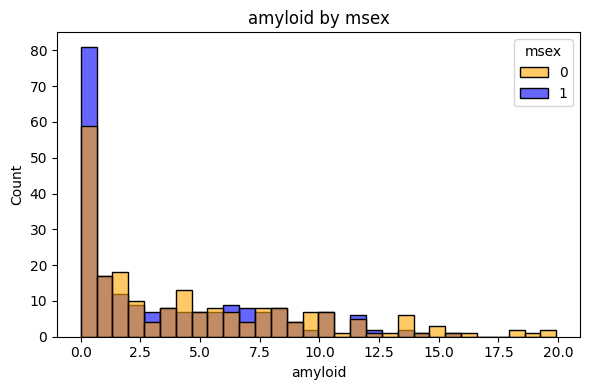

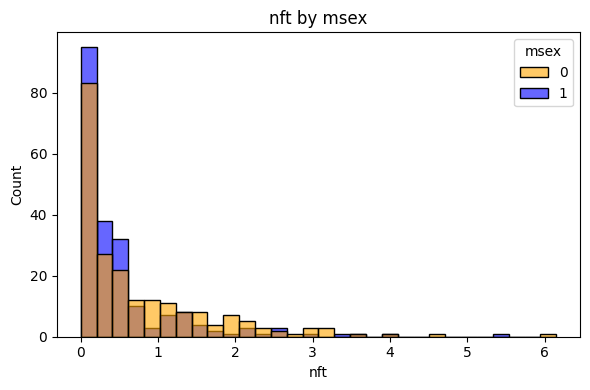

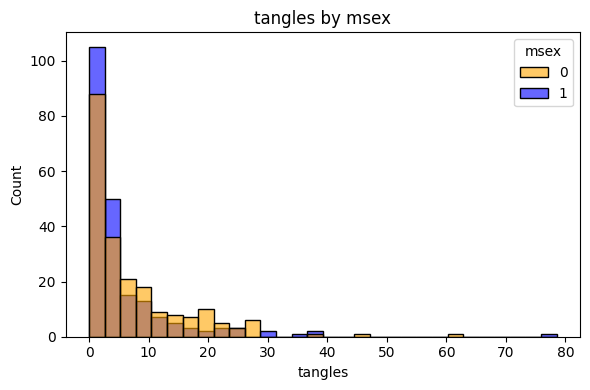

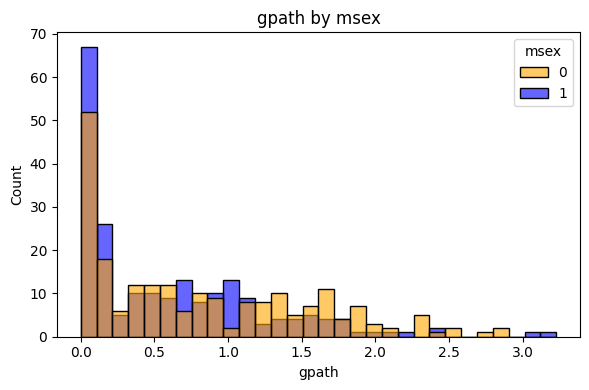

In [8]:
continuous_cols = ['age_death', 'amyloid', 'nft', 'tangles', 'gpath']

for col in continuous_cols:
    plt.figure(figsize=(6, 4))
    ax = sns.histplot(data=pheno_subset, x=col, hue='msex',
                      bins=30, multiple='layer', palette={1: 'blue', 0: 'orange'},
                      edgecolor="black", alpha=0.6)
    plt.title(f"{col} by msex")
    plt.xlabel(col)
    plt.ylabel("Count")
    plt.tight_layout()
    plt.show()
    plt.close()